In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi

In [3]:
prefix = '/mnt/staging/'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

# data_root =  str(PREPARES / "epochs-rest-to-running") + "/"
mouse='cm125'

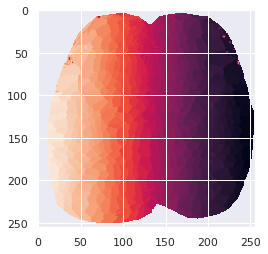

In [4]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
plt.imshow(IDX_sorted)

In [5]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


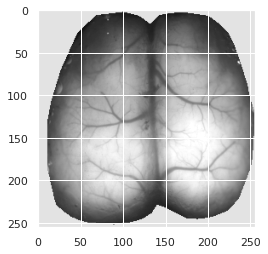

In [6]:
masked_brain_here = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain_here,nan=4000)
plt.imshow(masked_brain,cmap='gray',vmin=0,vmax=4500)

In [7]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#cd80a1'
palatte_dict['tail'] = 'palegreen'
palatte_dict['LT'] = '#b3b3b3'
palatte_dict['RT']  = '#e4c494' ##b69d76 back up
palatte_dict['RT']  = '#b69d76' # back up

In [9]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model

fetch_path = str(FIGURES / "figure1") + "/"
everything_dict_cm229 = load_model(fetch_path+'sensory_homunculus_cm229')
everything_dict_cm241 = load_model(fetch_path+'sensory_homunculus_cm241')

# homunculus_rois_S1 = everything_dict_cm229['homunculus_rois']
# homunculus_rois_cm241 = everything_dict_cm241['homunculus_rois']
# homunculus_rois_S1['LW']=homunculus_rois_cm241['LW']
# homunculus_rois_S1['RW']=homunculus_rois_cm241['RW']

clean_contours_S1 = load_model(fetch_path+'clean_contours_'+'cm229')
clean_contours_cm241 = load_model(fetch_path+'clean_contours_'+'cm241')
clean_contours_S1['LW']=clean_contours_cm241['LW'];
clean_contours_S1['RW']=clean_contours_cm241['RW'];

avg_brain_maps=everything_dict_cm229['avg_brain_maps']
vmax_dict=everything_dict_cm229['vmax_dict']
avg_brain_maps_addition=everything_dict_cm241['avg_brain_maps']
vmax_dict_addition=everything_dict_cm241['vmax_dict']
avg_brain_maps['LW'] = avg_brain_maps_addition['LW']
vmax_dict['LW'] = vmax_dict_addition['LW']
avg_brain_maps['RW'] = avg_brain_maps_addition['RW']
vmax_dict['RW'] = vmax_dict_addition['RW']

In [10]:
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

In [11]:
clean_contours_S1['LT'] = clean_contours_S1['tail'] 
clean_contours_S1['RT'] = clean_contours_S1['tail'] 
# homunculus_rois_S1['LT'] = homunculus_rois_S1['tail']
# homunculus_rois_S1['RT'] = homunculus_rois_S1['tail']
clean_contours_S1['LM'] = clean_contours_S1['mouth'] 
clean_contours_S1['RM'] = clean_contours_S1['mouth'] 
# homunculus_rois_S1['LM'] = homunculus_rois_S1['mouth']
# homunculus_rois_S1['RM'] = homunculus_rois_S1['mouth']
clean_contours_S1['LN'] = clean_contours_S1['nose'] 
clean_contours_S1['RN'] = clean_contours_S1['nose'] 
# homunculus_rois_S1['LN'] = homunculus_rois_S1['nose']
# homunculus_rois_S1['RN'] = homunculus_rois_S1['nose']

In [30]:
# (135,136) #bregma location
pixels_per_mm = 30
x_axis = np.divide(np.linspace(-135,256-135-1,256),pixels_per_mm)
y_axis = np.divide(np.linspace(256-136-1,-136,256),pixels_per_mm)
extent = [x_axis[0],x_axis[-1],y_axis[-1],y_axis[0]]


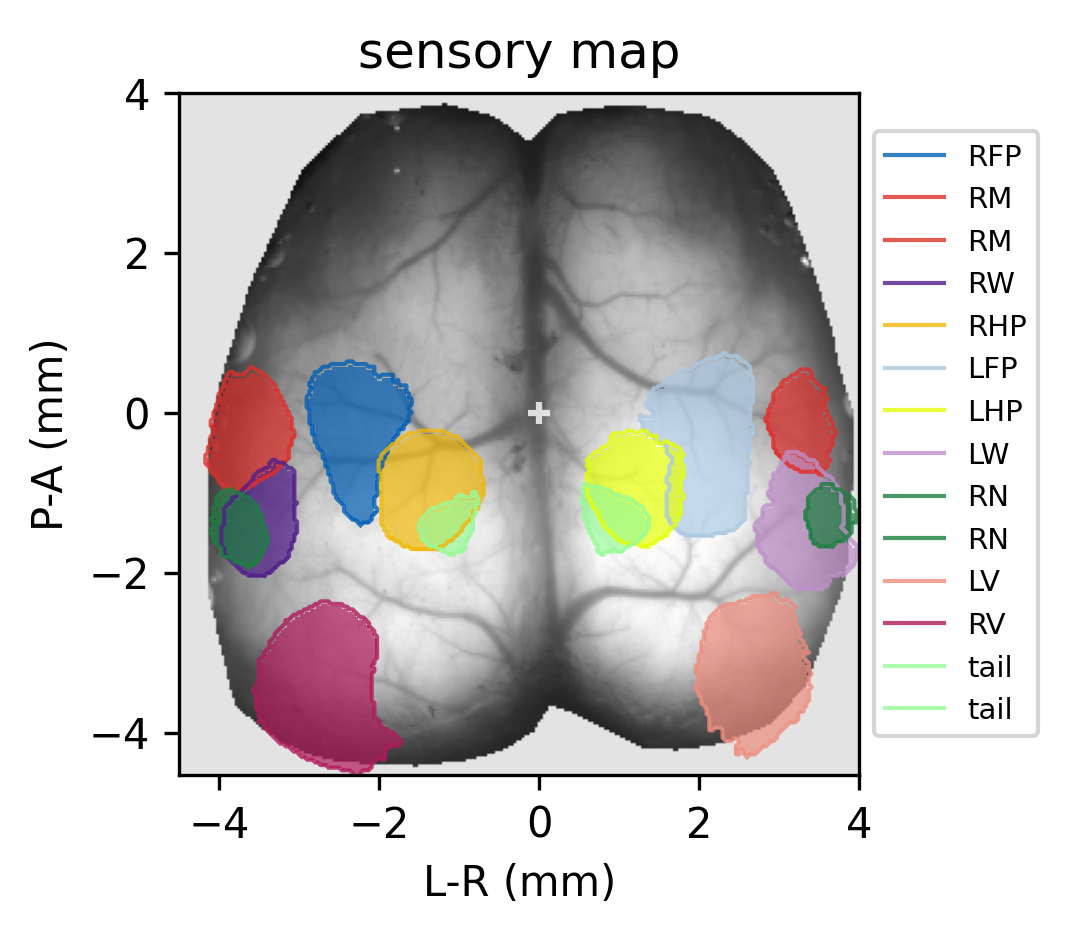

In [31]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)



y_offset = 20;x_offset=20;
x_width=10;

x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+10,x_start:x_stop])

ax0.imshow(masked_brain,cmap='gray',vmin=0,vmax=4500,extent=extent)

bdp_w_order = [ 'RFP', 'LM','RM', 'RW','RHP','LFP','LHP','LW','LN','RN','LV','RV','tail']
for ikey,bodypart_name in enumerate(bdp_w_order):
    if bodypart_name in ['LT','LN','LM']:
        # print(bodypart_name)
        continue
    bodypart_name_R =bodypart_name# 'R'+bodypart_name[1:]
    for contour in clean_contours_S1[bodypart_name]:
        # don't plot nose, tail, and mouth S1 
        # ===================
        r_mask = contour_to_roi(np.ones((256,256)),contour)
        c_black= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_R],alpha = 0.7)
        c_black1= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_R],alpha = 0.6)
        c_white= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_R],alpha = 0.5)
        cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)
        ax0.imshow(r_mask,vmin=0.1,vmax=1,cmap=cmap_rb,extent=extent)
        ax0.plot((contour[:,1]-135)/pixels_per_mm,(256-contour[:,0]-136)/pixels_per_mm,linewidth=1,alpha=0.8,
                 # linestyle='dashed',
                 label=bodypart_name,color=palatte_dict[bodypart_name_R])



        
ax0.scatter(0,0,s=30,marker='+',color='white',alpha=0.8) #bregma location
ax0.legend(loc='center left',fontsize=7, bbox_to_anchor=(1, 0.5))
ax0.set_title('sensory map')
ax0.set_xlabel('L-R (mm)')
ax0.set_ylabel('P-A (mm)')
ax0.set_xticks([-4,-2,0,2,4])
ax0.set_yticks([-4,-2,0,2,4])

plt.savefig('fig1-S1-topography.svg',format='svg',dpi=300)



# Boop test

In [20]:
fire_cmap = load_pickle(figure_config_root+'fire_cmap')

In [21]:
bdp_short_dict = {'LFP':'FP(L)','LHP':'HP(L)','LM':'mouth(L)','LW':'whisker(L)',
                  'LN':'nose(L)','RFP':'FP(R)','RHP':'HP(R)','RM':'mouth(R)',
                  'RW':'whisker(R)','RN':'nose(R)','LV':'visual(L)','RV':'visual(R)',
                 'RT':'tail(R)','LT':'tail(L)',
                 'mouth':'mouth','nose':'nose','tail':'tail'}

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:41: MatplotlibDeprecationWarning: You are modifying the state of a globally registered colormap. This has been deprecated since 3.3 and in 3.6, you will not be able to modify a registered colormap in-place. To remove this warning, you can make a copy of the colormap first. cmap = mpl.cm.get_cmap("icefire").copy()


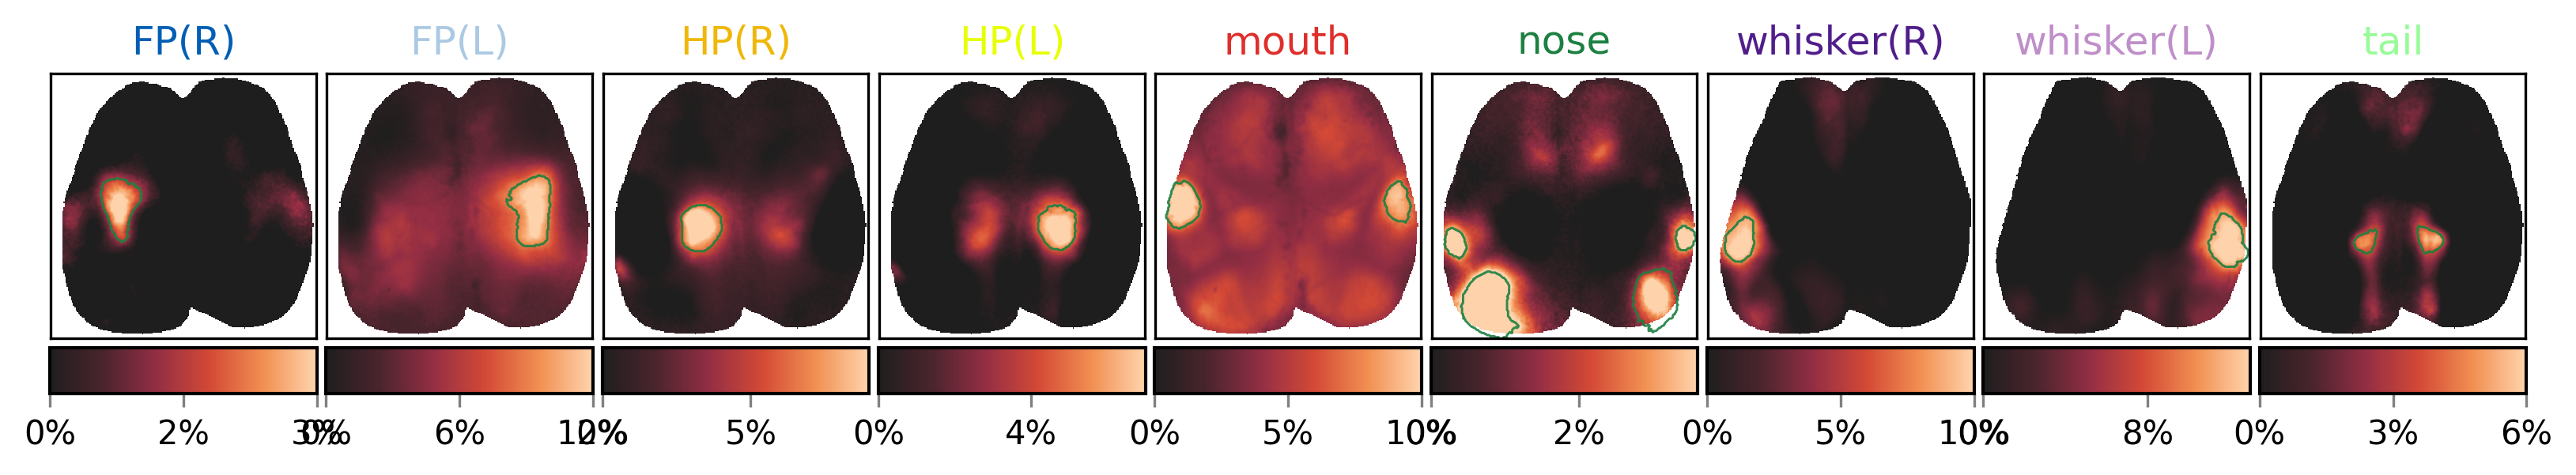

In [22]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')

fmt = lambda x, pos: '{:.0%}'.format(x)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable


gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=4

x_start = x_offset
for i_ax in range(9):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_start+5])".format(i_ax))
    x_start = x_start+5+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
x_start = x_offset
for i_ax in range(9,18):
    exec("ax{} = fig.add_subplot(gs[y_offset+5:y_offset+6,x_start:x_start+5])".format(i_ax))
    x_start = x_start+5+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))    


########################################################################

cmap = matplotlib.cm.get_cmap('icefire')  
cmap.set_bad(color='white')

body_list=[ 'RFP','LFP', 'RHP','LHP','mouth', 'nose','RW','LW','tail']
for i_ax, bdp in enumerate(body_list):
    exec("sbp{} = ax{}.imshow(np.multiply(mask,avg_brain_maps[bdp]),vmin=-0.0,vmax=vmax_dict[bdp],aspect='equal',cmap=fire_cmap)".format(i_ax,i_ax))
    for contour in clean_contours_S1[bdp]:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.7,alpha=0.9,label=bdp,color='#1c8041')".format(i_ax))
        exec("ax{}.set_title(bdp_short_dict[bdp],color=palatte_dict[bdp])".format(i_ax))
    if bdp in ['nose']:
        for name in ['LV','RV']:
            for contour in clean_contours_S1[name]:
                exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.7,alpha=0.9,label=bdp,color='#1c8041')".format(i_ax))
        exec("ax{}.set_xlabel(bdp.replace('W','V'),color=palatte_dict[bdp])".format(i_ax))
        
        
for i_ax, bdp in enumerate(body_list):
    exec("cb = fig.colorbar(sbp{}, cax=ax{},fraction=0.3,orientation='horizontal',format=FuncFormatter(fmt));".format(i_ax,i_ax+9))
    cb.ax.tick_params(labelsize=10,length=4,color='gray')
    # cb.ax.yaxis.tick_right()       
    cb.outline.set_edgecolor('black')
    cb.outline.set_linewidth(1)
    tick_locator = ticker.MaxNLocator(nbins=2)
    cb.locator = tick_locator
    cb.update_ticks()
    exec("ax{}.set_anchor('N')".format(i_ax+9))
    # exec("ax{}.set_aspect(0.006)".format(i_ax+9))


# for i_t,i_ax in enumerate(range(0,7)):
#     exec("ax{}.set_title('t=t{}')".format(i_t,i_t+1))
    
# for i_part,part in enumerate(['top','bottom','left','right']):
#     for i_t,i_ax in enumerate(range(0,7)):
#         exec("ax{}.spines[part].set_linewidth(0.5)".format(i_t))
#         exec("ax{}.spines[part].set_color('black')".format(i_t))
#         exec("ax{}.spines[part].set_linestyle('dashed') ".format(i_t))

#     ax0.spines[part].set_linewidth(.5) 
    
# # # img2 = np.array(enhanced_output)[90:320,100:360,:]

plt.savefig('fig1-boop-test.svg',format='svg',dpi=300)



# part 3 consistency

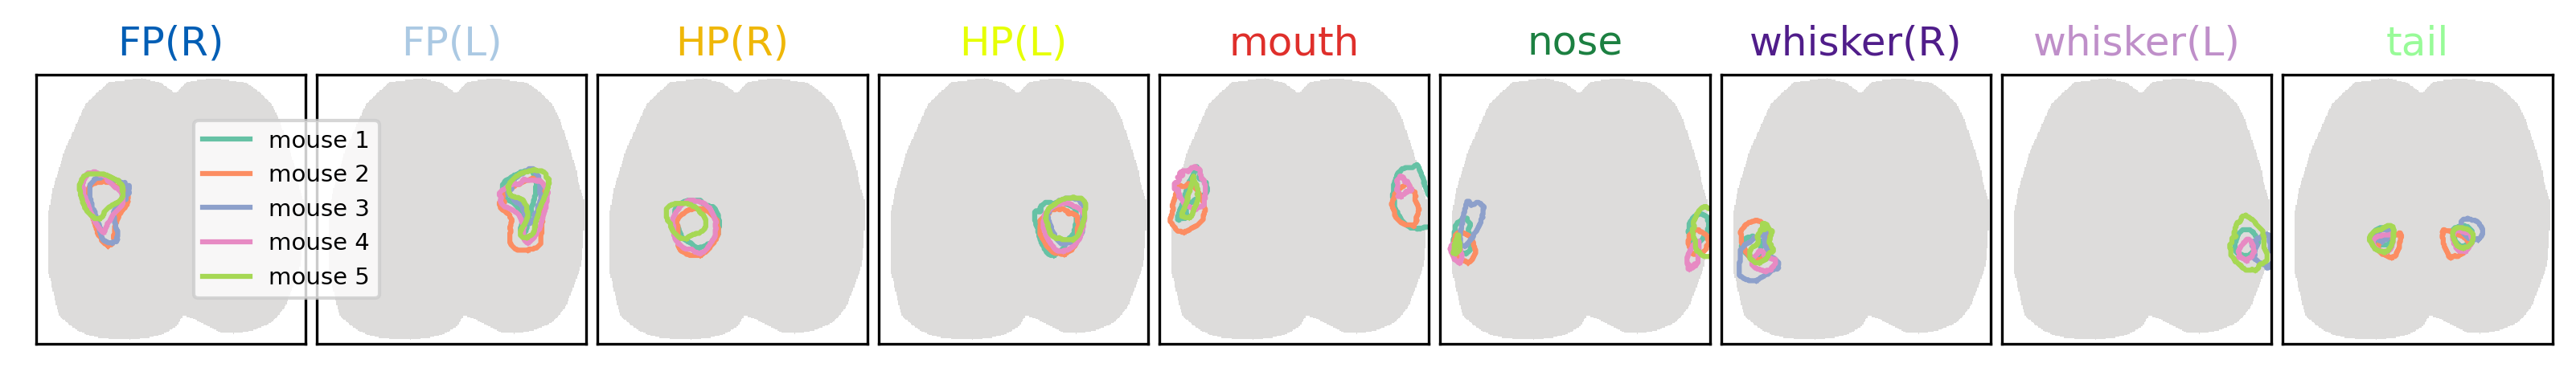

In [81]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')

fmt = lambda x, pos: '{:.0%}'.format(x)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable


gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=4

x_start = x_offset
for i_ax in range(9):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_start+5])".format(i_ax))
    x_start = x_start+5+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
# x_start = x_offset
# for i_ax in range(9,18):
#     exec("ax{} = fig.add_subplot(gs[y_offset+5:y_offset+6,x_start:x_start+5])".format(i_ax))
#     x_start = x_start+5+x_gap
#     exec("ax{}.set_yticks([])".format(i_ax))
#     exec("ax{}.set_xticks([])".format(i_ax))    


########################################################################
load_path = str(PREPARES / "sensory-boop-test") + "/"

body_list=[ 'RFP','LFP', 'RHP','LHP','mouth', 'nose','RW','LW','tail']
mice = ['cm193','cm229','cm216','cm265','cm241']
palette = sns.color_palette("Set2")
combine_homunculus = {bdp: np.empty((256,256,0)) for bdp in body_list}
for i_mouse,mouse_id in enumerate(mice):
    for i_ax, bdp in enumerate(body_list):
        # sbp = plt.imshow(mask,vmin=0,vmax=2,cmap='coolwarm')

        exec("sbp{} = ax{}.imshow(mask,vmin=-0.0,vmax=2,aspect='equal',cmap='coolwarm')".format(i_ax,i_ax))
        exec("ax{}.set_title(bdp_short_dict[bdp],color=palatte_dict[bdp])".format(i_ax))
        clean_contours_here = load_model(load_path+'clean_contours_'+mouse_id)
        try:
            for i_contour,contour in enumerate(clean_contours_here[bdp]):
                exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1.5,color=palette[i_mouse],label='mouse '+str(i_mouse+1))".format(i_ax))
                if np.logical_and(i_contour==0,i_ax==1):
                    exec("ax{}.legend(loc='center left',fontsize=7, bbox_to_anchor=(-0.5, 0.5))".format(i_ax))
        except:
            continue




plt.savefig('fig1-boop-consistency.svg',format='svg',dpi=300)

